# Evaluation of the expert pools

AUROC of every expert (rows) on every generator's images (columns), for the ResNet pool and the CLIP pool.
Both read the saved expert scores (`resnet/score.py`, `clip/score.py`), so run those notebooks first. See `common/evaluation.py`.

- **Diagonal ≈ 1.0:** each expert detects its own generator(s).
- **Siblings high:** SD ↔ wukong, ADM → glide / BigGAN.
- **Off-diagonal:** how well an expert transfers to generators it never saw.

A low diagonal means training went wrong. *Everything* ≈ 1.0 points to a shortcut (image size or JPEG traces).
`test` is not looked at.

In [11]:
import sys
sys.path.insert(0, "..")  # repo root, so `clip`, `common`, `data` and `resnet` are importable

from clip.score import SCORES_NAME as CLIP_SCORES
from common.evaluation import cross_auroc, plot_cross_auroc
from resnet.score import feature_name

ARCH = "resnet18"  # the ResNet experts to evaluate
LIMIT = None  # the limit of a ResNet test run, None for the full run
POOL = "meta_val"

## ResNet experts

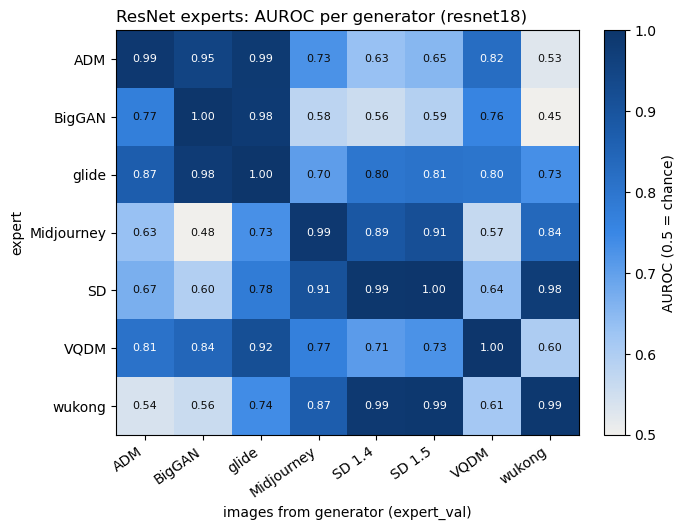

,ADM,BigGAN,glide,Midjourney,stable_diffusion_v_1_4,stable_diffusion_v_1_5,VQDM,wukong
ADM,0.988,0.952,0.986,0.727,0.632,0.654,0.823,0.526
BigGAN,0.772,1.000,0.983,0.579,0.555,0.592,0.757,0.453
glide,0.871,0.979,1.000,0.703,0.798,0.807,0.802,0.734
Midjourney,0.631,0.477,0.732,0.990,0.889,0.914,0.565,0.838
SD,0.669,0.595,0.780,0.908,0.995,0.998,0.640,0.977
VQDM,0.809,0.843,0.917,0.768,0.708,0.727,0.997,0.602
wukong,0.538,0.560,0.740,0.871,0.988,0.991,0.613,0.992


In [12]:
resnet_table = cross_auroc(feature_name(ARCH, LIMIT), POOL)
plot_cross_auroc(resnet_table, f"ResNet experts: AUROC per generator ({ARCH})", POOL)
resnet_table.round(3)

## CLIP experts

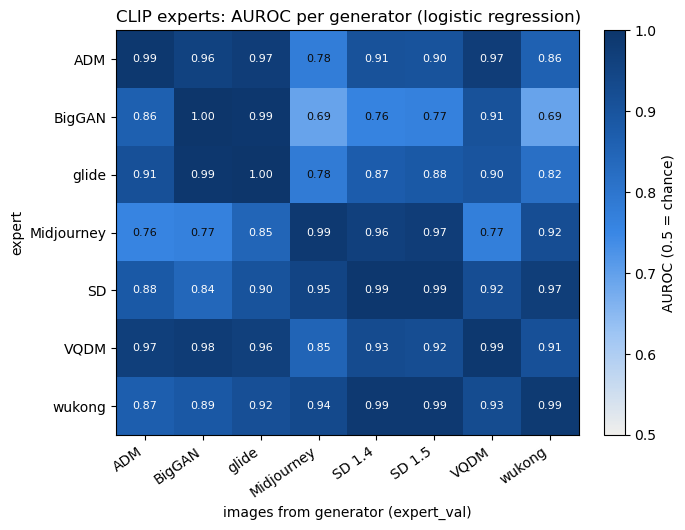

,ADM,BigGAN,glide,Midjourney,stable_diffusion_v_1_4,stable_diffusion_v_1_5,VQDM,wukong
ADM,0.992,0.957,0.973,0.777,0.907,0.903,0.973,0.858
BigGAN,0.863,1.000,0.994,0.693,0.758,0.766,0.907,0.692
glide,0.912,0.993,0.999,0.785,0.872,0.883,0.899,0.817
Midjourney,0.756,0.766,0.847,0.988,0.964,0.973,0.773,0.921
SD,0.885,0.840,0.904,0.950,0.994,0.993,0.920,0.972
VQDM,0.968,0.977,0.965,0.850,0.929,0.923,0.991,0.912
wukong,0.866,0.887,0.915,0.935,0.986,0.987,0.928,0.986


In [13]:
clip_table = cross_auroc(CLIP_SCORES, POOL)
plot_cross_auroc(clip_table, "CLIP experts: AUROC per generator (logistic regression)", POOL)
clip_table.round(3)